In [132]:

import scipy.stats
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
from matplotlib.ticker import MaxNLocator
from BWM.ScriptsandFunctions.bwm_functions import *

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [60]:
# Set directory path and select an EID
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]


In [61]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks'

In [62]:
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')



In [63]:

def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])

    X_transposed = response_matrix.T

    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)

    # Reduce features to 20 using PCA

    return X_pre_pca

X = iso_ae_preprocessing(pseudo_response_tensor)

In [68]:
z_neurons= umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X)


In [64]:
def calculate_msd(response_matrix):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_matrix_expand = response_matrix.reshape( response_matrix.shape[0],100,2)
    diff_responses = np.diff(response_matrix_expand, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
    msd = np.mean(np.abs(diff_responses), axis=(1, 2))
    return msd

msd = calculate_msd(X)


In [65]:


def generate_constrained_orthogonal_matrix(n, epsilon):
    """
    Generates a random orthogonal matrix Q of shape (n, n) whose
    distance from the Identity matrix is scaled by epsilon.

    Parameters:
    -----------
    n : int
        The dimension of the matrix (n x n).
    epsilon : float
        Distance parameter (epsilon >= 0).
        0 yields exactly the Identity matrix.
        Small values yield matrices very close to Identity.
        Large values yield highly randomized rotations.

    Returns:
    --------
    Q : ndarray of shape (n, n)
        A random orthogonal matrix.
    """
    if epsilon < 0:
        raise ValueError("Epsilon must be greater than or equal to 0.")

    # 1. Generate a raw random matrix
    A_raw = np.random.randn(n, n)

    # 2. Make it skew-symmetric: A = A_raw - A_raw^T
    # This guarantees that A^T = -A
    A_skew = A_raw - A_raw.T

    # 3. Normalize the matrix norm so epsilon has a predictable scaling effect
    # We use the Frobenius norm to normalize the matrix scale
    norm = np.linalg.norm(A_skew, ord='fro')
    if norm > 0:
        A_skew = A_skew / norm

    # 4. Scale by our epsilon distance parameter
    A_scaled = epsilon * A_skew

    # 5. Project onto the Orthogonal Group using the Matrix Exponential
    Q = expm(A_scaled)

    return Q




KeyboardInterrupt: 

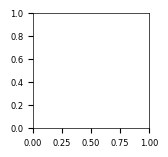

In [66]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(1.5, 1.5), sharey=False)
"""
Plots the distribution of a coefficient list and draws a vertical line at r
with a completely clean background (no grid lines).
"""

# Null distribution
z  = get_density_proxy(X, k=50)
r,_ = scipy.stats.spearmanr(msd, z)
coeffs = []
for i in range(5000):
    Q =scipy.stats.ortho_group.rvs(X.shape[1])
    #Q = generate_constrained_orthogonal_matrix(X.shape[1], np.random.rand())
    rotated_X = X @ Q

    diff_responses = np.diff(rotated_X, axis=1)
    msd_rotated = np.mean(np.abs(diff_responses), 1)
    coeff,_ = scipy.stats.spearmanr(msd_rotated, z)
    coeffs.append(coeff)
coeffs = np.asarray(coeffs)
# sns.histplot(coeffs, kde=False,color='k',legend=False,ax=axes[0,0])
# axes[0,0].axvline(x=r, color="#d9534f", linestyle="--", linewidth=1,
#             label=f"Reference Value ($r$ = {r:.3f})",alpha = .5)
# p_value = np.sum(coeffs>r)/len(coeffs)






In [67]:
def plot_coefficients_distribution(coeffs, r, figsize=(3, 3)):
    """
    Plots the distribution of a coefficient list and draws a vertical line at r
    with a completely clean background (no grid lines).
    """
    coeffs = np.asarray(coeffs)

    plt.figure(figsize=figsize)

    # 1. Plot the continuous kernel density estimate (KDE) and histogram
    sns.histplot(coeffs, kde=True, stat="density")

    # 2. Draw the vertical line at r
    plt.axvline(x=r, color="#d9534f", linestyle="--", linewidth=2.5,
                label=f"Reference Value ($r$ = {r:.3f})")

    # 3. Aesthetics and Labels
#    plt.title("Distribution of Coefficients", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Coefficient Value", fontsize=7)
    plt.ylabel("Density", fontsize=7)

    # Explicitly turn off the grid lines
    plt.grid(False)

    # Clean up the spines (border boxes) for a minimal look
    sns.despine()

    plt.legend(frameon=True, facecolor='white', edgecolor='none')
    plt.tight_layout()
    plt.show()


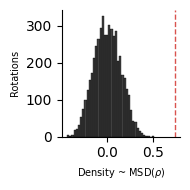

In [208]:
plot_coefficients_distribution(coeffs, r, figsize=(2, 2))

# Plot original density

In [13]:
X.shape

(7940, 200)

# Visualize effect of rotations

NameError: name 'z_neurons' is not defined

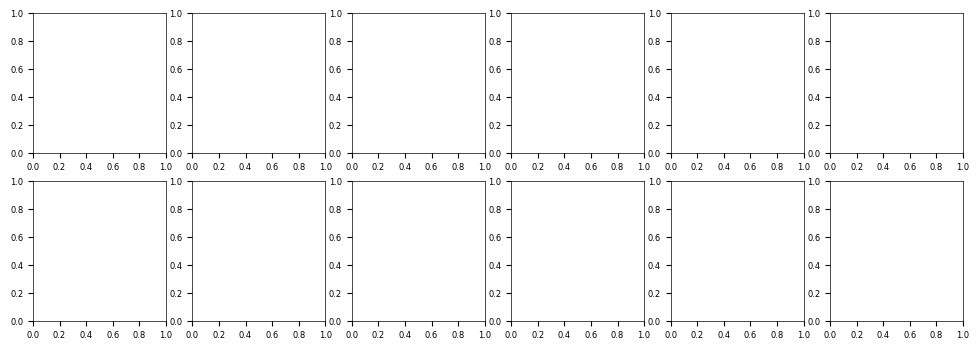

In [8]:
import numpy as np


def generate_orthogonal_family(n, seed=None):
    """
    Creates and returns a continuous 1D trajectory function for orthogonal matrices.

    Parameters:
    -----------
    n : int
        The dimension of the square matrix (n x n).
    seed : int, optional
        Random seed to make the generated path reproducible.

    Returns:
    --------
    path_function : function
        A function that takes a scalar `t` and returns an (n x n) orthogonal matrix.
    """
    if seed is not None:
        np.random.seed(seed)

    # 1. Generate a random matrix and convert it to a skew-symmetric matrix (A^T = -A)
    # This acts as the constant "velocity vector" in the Lie algebra.
    A_raw = .1*np.random.randn(n, n)
    A_skew = A_raw - A_raw.T

    # 2. Normalize the Frobenius norm so that the parameter t has a predictable scale
    norm = np.linalg.norm(A_skew, ord='fro')
    if norm > 0:
        A_skew = A_skew / norm

    # 3. Define the continuous 1D path function
    def path_function(t):
        if t < 0:
            raise ValueError("The parameter t must be greater than or equal to 0.")
        # Compute Q(t) = exp(t * A)
        return expm(t * A_skew)

    return path_function



fig, axes = plt.subplots(nrows=2, ncols=6, figsize=(12, 4), sharex=False, sharey=False)

# 3. Loop through the axes and variables simultaneously
#X = iso_ae_preprocessing(pseudo_response_tensor)

# Fit autoencoder
loc_density  = get_density_proxy(X, k=50)

Q_path = generate_orthogonal_family(X.shape[1], seed=42)
for col in range(6):

    # --- ROW 1: TOP PLOT ---
    ax_top = axes[0, col]
    ax_bottom = axes[1, col]
    X_rotated = X @ Q_path(col)
    msd_rotated = calculate_msd(X_rotated)
#     autoencoder = SklearnIsometricAutoencoder(
#     latent_dim=2, hidden_dim=64, depth=4,
#     epochs=25, batch_size=128,
#     lambda_iso=0.01, lambda_density=0.01, verbose=False, device=device, patience=100,
#     lr=0.001, r2_diff_threshold=0.02
# )
#     autoencoder.fit(X_rotated)

    #z_neurons = autoencoder.transform(X_rotated)
    # Plot the scatterplot on the specific axis 'ax'
    # Subplot 2: Colored by MSD
    vmin_msd, vmax_msd = np.percentile(msd, [1, 99])
    range_msd = vmax_msd - vmin_msd
    vmin_msd -= 0.1 * range_msd
    vmax_msd += 0.1 * range_msd
    sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated,cmap='turbo', s=3, alpha=.5,ax=ax_top)
    sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap='turbo',s=3, alpha=.25,ax=ax_bottom)

    # Correlation
    r,_ = scipy.stats.spearmanr(msd_rotated, loc_density)
#    ax_top.set_title(f"Density-MSD corr.: {r:.2f}", fontsize=6)
    ax_top.axis('off')
    ax_bottom.axis('off')
   # ax.grid(False) # Grid off as requested in previous styles

# 4. Final layout tuning
sns.despine() # Clean top and right borders
plt.tight_layout() # Automatically adjusts spacing between plots to prevent overlap

# Display the row
plt.savefig("RotationTest_trajectory.png", bbox_inches='tight', dpi=300)
plt.show()

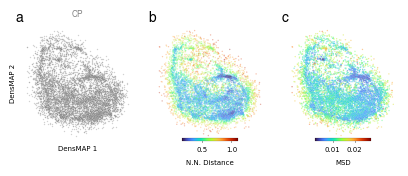

In [312]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(8, 1.5))

gs = gridspec.GridSpec(1, 5, width_ratios=[1, 1, 1,1,.8])

# Assign your subplots to the grid slots, skipping the spacer slot (index 2)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
# Index 2 is intentionally left blank as a gap
ax3 = plt.subplot(gs[2])

# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=1, alpha=.35,ax=ax1)

# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=loc_density,cmap  = 'turbo', s=1, alpha=.35,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(loc_density.min(), loc_density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd,cmap='turbo', s=1, alpha=.5,ax=ax3)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd.min(), msd.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)



# Rotation 1
Q = scipy.stats.ortho_group.rvs(X.shape[1])
X_rotated = X @ Q
msd_rotated = calculate_msd(X_rotated)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated,cmap='turbo', s=1, alpha=.5,ax=ax4)
cax = inset_axes(
        ax4, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd_rotated.min(), msd_rotated.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="k")
cax.xaxis.set_tick_params(labelsize=5)

# Null distribution
sns.histplot(coeffs, stat="probability",ax=ax5,color='gray')
ax5.axvline(x=r, color="#d9534f", linestyle="--", linewidth=.5,
                label=f"Reference Value ($r$ = {r:.3f})")

ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)
ax5.spines['bottom'].set_position(('data', 0))
ax5.tick_params(axis='both', which='major', labelsize=5, length=3)
ax5.set_ylabel('Probability', fontsize=6)
ax5.set_xlabel('Correlation', fontsize=6)
pos = ax5.get_position()
from matplotlib.transforms import Bbox
new_pos = Bbox.from_bounds(
    pos.x0 + 0.05,     # New Left
    pos.y0 + 0.05,     # New Bottom
    pos.width -0,  # New Width
    pos.height - 0.15  # New Height
)
# 3. Apply the new position back to ax1
ax5.set_position(new_pos)
ax5.yaxis.set_major_locator(MaxNLocator(nbins=3))
# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3,ax4]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')

ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.set_ylabel('', fontsize=2)
ax4.set_xlabel('', fontsize=5)
ax4.tick_params(axis='both', which='major', labelsize=6, length=3)
#ax4.set_title('Rotation',fontsize= 6,alpha =.5)

ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)



#fig.subplots_adjust(wspace=0.2)

# Figure labels
ax1.text(-0.05, 1.01, 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1.01, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1.01, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax4.text(-0.05, 1.01, 'd', transform=ax4.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax5.text(-.5, 1.01, 'e', transform=ax5.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')


# Subfigure titles
#ax1.set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)

#ax5.set_title('Null distribution\n',fontsize = 6,fontname = 'Helvetica')
# axes[3].set_title('Rotation 1',fontsize = 6,fontname = 'Helvetica')
# 5. Display or save the plot
#plt.tight_layout()
plt.savefig("CPRotations.png", bbox_inches='tight', dpi=300)



In [308]:
X.shape

(7940, 200)

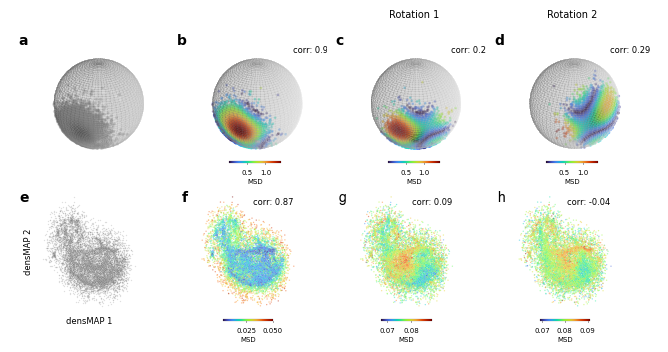

In [157]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.stats import gaussian_kde

def generate_inverse_msd_distribution(n=1000, seed=42, localized=False):
    if seed is not None:
        np.random.seed(seed)
    
    points = []
    
    # Define some centers for localized sampling if needed
    if localized:
        n_modes = 3
        centers = np.random.randn(n_modes, 3)
        centers /= np.linalg.norm(centers, axis=1, keepdims=True)
        
    # Rejection sampling
    while len(points) < n:
        # Sample uniformly on the sphere
        sample = np.random.randn(200, 3)
        sample /= np.linalg.norm(sample, axis=1, keepdims=True)
        
        # Calculate MSD for these samples
        msd_vals = calculate_synthetic_msd(sample)
        
        # Base density proportional to 1/MSD
        # Use a smaller epsilon to make the relationship more apparent
        density = 1.0 / (msd_vals + 0.01)
        
        if localized:
            # Apply a localization mask (multimodal)
            # We want density to be non-zero only near centers
            localization = np.zeros(len(sample))
            for c in centers:
                # Use a Gaussian-like decay from centers
                dist_sq = np.sum((sample - c)**2, axis=1)
                # Smaller variance for localization (0.3 instead of 0.5)
                # to make the density vary more significantly within the modes
                # localization += np.exp(-dist_sq / (2 * .3**2))
                # Actually, let's use a hard threshold for localization to not wash out MSD
                localization[dist_sq < 0.5**2] = 1.0
            
            density *= localization
            
        # Max density for rejection sampling
        max_d = np.max(density) * 1.1 if localized else 10.0
        
        # Rejection sampling
        r = np.random.rand(len(sample)) * max_d
        accepted = sample[r < density]
        points.extend(accepted)
        
    return np.array(points)[:n]

def generate_multimodal_sphere(n=5000, n_modes=3, seed=42, cover_sphere=False):
    if seed is not None:
        np.random.seed(seed)
    
    # Generate points around several centers
    points = []
    centers = np.random.randn(n_modes, 3)
    centers /= np.linalg.norm(centers, axis=1, keepdims=True)
    
    if cover_sphere:
        # Increase points_per_mode and variance to cover more area
        points_per_mode = (n * 2) // (n_modes * 3) 
        for i in range(n_modes):
            # Increased variance from 0.3 to 0.8 to cover more area
            mode_points = centers[i] + 2 * np.random.randn(points_per_mode, 3)
            points.append(mode_points)
        
        # Add significant background noise to cover the whole sphere
        remaining = n - points_per_mode * n_modes
        if remaining > 0:
            points.append(np.random.randn(remaining, 3))
    else:
        # Localized modes
        points_per_mode = n // n_modes
        for i in range(n_modes):
            # Smaller variance to stay localized
            mode_points = centers[i] + 0.15 * np.random.randn(points_per_mode, 3)
            points.append(mode_points)
    
    X = np.vstack(points)
    # Normalize to sphere
    X /= np.linalg.norm(X, axis=1, keepdims=True)
    return X

def draw_smooth_sphere(ax, X, mode='density', cmap='turbo', alpha=0.8, show_boundary=False, threshold=0.1):
    # Create a grid for the sphere
    u = np.linspace(0, 2 * np.pi, 60)
    v = np.linspace(0, np.pi, 60)
    u_grid, v_grid = np.meshgrid(u, v)
    
    x = np.cos(u_grid) * np.sin(v_grid)
    y = np.sin(u_grid) * np.sin(v_grid)
    z = np.cos(v_grid)
    
    # Reshape grid to (N, 3) to evaluate estimates
    grid_points = np.stack([x.flatten(), y.flatten(), z.flatten()], axis=1)
    
    kde = gaussian_kde(X.T)
    density_values = kde(grid_points.T)
    
    if mode == 'density':
        values = density_values
    else: # mode == 'msd'
        values = calculate_synthetic_msd(grid_points)
    
    values = values.reshape(x.shape)
    density_values = density_values.reshape(x.shape)
    
    # Normalize values for colormap
    norm = plt.Normalize(values.min(), values.max())
    colors = plt.colormaps[cmap](norm(values))
    
    if show_boundary:
        # Create a mask for points outside the distribution
        # We use a threshold on density
        mask = density_values < threshold
        colors[mask] = [0.8, 0.8, 0.8, alpha] # Light gray
    
    ax.plot_surface(x, y, z, facecolors=colors, alpha=alpha, linewidth=0, antialiased=False, rstride=1, cstride=1)

def draw_sphere(ax):
    u = np.linspace(0, 2 * np.pi, 30)
    v = np.linspace(0, np.pi, 30)
    x = np.outer(np.cos(u), np.sin(v))
    y = np.outer(np.sin(u), np.sin(v))
    z = np.outer(np.ones(np.size(u)), np.cos(v))
    ax.plot_surface(x, y, z, color='lightgray', alpha=0.1, linewidth=0)

def generate_deformed_disc(n=1000, radius=0.5, seed=42):
    if seed is not None:
        np.random.seed(seed)
    
    # Choose a random center on the sphere
    center = np.random.randn(3)
    center /= np.linalg.norm(center)
    
    # Basis for the tangent plane at center
    v1 = np.random.randn(3)
    v1 -= np.dot(v1, center) * center
    v1 /= np.linalg.norm(v1)
    v2 = np.cross(center, v1)
    
    points = []
    while len(points) < n:
        # Sample points in the tangent plane (deformed disc)
        r = radius * np.sqrt(np.random.rand(n * 2))
        theta = 2 * np.pi * np.random.rand(n * 2)
        
        # Add some deformation (e.g., sine wave modulation of radius)
        modulation = 1 + 0.2 * np.sin(2 * theta) +0.2 * np.cos(3 * theta)**2
        r *= modulation
        
        # Mapping from tangent plane to sphere
        x_p = r[:, np.newaxis] * (np.cos(theta)[:, np.newaxis] * v1 + np.sin(theta)[:, np.newaxis] * v2)
        
        # Exponential map: x = center * cos(r) + (x_p/r) * sin(r)
        r_val = np.linalg.norm(x_p, axis=1, keepdims=True)
        r_val = np.maximum(r_val, 1e-10)
        p = center * np.cos(r_val) + (x_p / r_val) * np.sin(r_val)
        
        points.extend(p)
    
    return np.array(points)[:n]

def calculate_synthetic_msd(X):
    # Invent a smooth 'mean derivative' proxy that depends on position
    # This simulates a distribution where some areas have higher "derivatives"
    return np.abs(np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1]) + 0.5 * X[:, 2])

def calculate_density(X):
    # Use Gaussian KDE to estimate density
    # Transpose because gaussian_kde expects (d, n)
    kde = gaussian_kde(X.T)
    return kde(X.T)

def sample_gaussian_msd(n=1000, sigma=0.5, seed=42):
    if seed is not None:
        np.random.seed(seed)
    
    # 1. Find a point with high MSD
    # Generate many points and pick the one with max MSD
    n_search = 10000
    phi_search = np.random.uniform(0, 2 * np.pi, n_search)
    cos_theta_search = np.random.uniform(-1, 1, n_search)
    theta_search = np.arccos(cos_theta_search)
    
    x_s = np.sin(theta_search) * np.cos(phi_search)
    y_s = np.sin(theta_search) * np.sin(phi_search)
    z_s = np.cos(theta_search)
    X_search = np.stack([x_s, y_s, z_s], axis=1)
    msd_search = calculate_synthetic_msd(X_search)
    center = X_search[np.argmax(msd_search)]
    
    # 2. Sample from a Gaussian centered on this point in the tangent plane
    # Get tangent basis
    if np.abs(center[2]) > 0.9:
        v1 = np.array([1, 0, 0])
    else:
        v1 = np.array([0, 0, 1])
    v1 = v1 - np.dot(v1, center) * center
    v1 /= np.linalg.norm(v1)
    v2 = np.cross(center, v1)
    
    # Sample Gaussian in 2D tangent space
    z2d = np.random.normal(0, sigma, (n, 2))
    x_p = z2d[:, 0:1] * v1 + z2d[:, 1:2] * v2
    
    # Exponential map: x = center * cos(r) + (x_p/r) * sin(r)
    r_val = np.linalg.norm(x_p, axis=1, keepdims=True)
    r_val_clamped = np.maximum(r_val, 1e-10)
    X_sampled = center * np.cos(r_val) + (x_p / r_val_clamped) * np.sin(r_val)
    
    return X_sampled

# Generate a distribution sampled from a Gaussian centered at a high MSD point
n_samples = 5000
X_sampled = sample_gaussian_msd(n=n_samples, sigma=.3, seed=42)

# Generate uniform samples for the first subplot
n_uniform = 10000
phi_u = np.random.uniform(0, 2 * np.pi, n_uniform)
cos_theta_u = np.random.uniform(-1, 1, n_uniform)
theta_u = np.arccos(cos_theta_u)
x_u = np.sin(theta_u) * np.cos(phi_u)
y_u = np.sin(theta_u) * np.sin(phi_u)
z_u = np.cos(theta_u)
X_uniform = np.stack([x_u, y_u, z_u], axis=1)

# Create the figure with 2 rows: 4 subplots in top row, 1 in bottom row
fig = plt.figure(figsize=(8, 4))
gs = gridspec.GridSpec(2, 4, height_ratios=[1, 1], hspace=-0.2, wspace=0.1)

# Subplot 1: Original unrotated distribution (Black points)
ax0 = fig.add_subplot(gs[0, 0], projection='3d')
pos0 = ax0.get_position()
ax0.set_position([pos0.x0 - pos0.width * 0.1, pos0.y0 - pos0.height * 0.1, pos0.width * 1.2, pos0.height * 1.2])
draw_smooth_sphere(ax0, X_sampled, mode='density', cmap='Greys', alpha=0.1, show_boundary=True, threshold=0.01)
ax0.scatter(X_sampled[:, 0], X_sampled[:, 1], X_sampled[:, 2], color='gray', s=2, alpha=0.25)
draw_sphere(ax0)
#ax0.set_title("Original Distribution", fontsize=8)
ax0.set_box_aspect([1,1,1])
ax0.axis('off')
ax0.text2D(0.05, 0.92, "a", transform=ax0.transAxes, fontsize=10, fontweight='bold', va='top')

# Subplot 2: Sampled distribution colored by MSD (Individual samples)
ax2 = fig.add_subplot(gs[0, 1], projection='3d')
pos2 = ax2.get_position()
ax2.set_position([pos2.x0 - pos2.width * 0.1, pos2.y0 - pos2.height * 0.1, pos2.width * 1.2, pos2.height * 1.2])
draw_smooth_sphere(ax2, X_sampled, mode='density', cmap='Greys', alpha=0.1)
msd_vals2 = calculate_synthetic_msd(X_sampled)
density2 = calculate_density(X_sampled)
r_b, _ = scipy.stats.spearmanr(msd_vals2, density2)
ax2.text2D(0.95, 0.85, f"corr: {r_b:.2f}", transform=ax2.transAxes, fontsize=6, va='top', ha='right')
#ax2.set_title(fr" $\rho$: {r_b:.2f}", fontsize=7)
ax2.scatter(X_sampled[:, 0], X_sampled[:, 1], X_sampled[:, 2], c=msd_vals2, cmap='turbo', s=1, alpha=0.4)
draw_sphere(ax2)
#ax2.set_title("Sampled Dist (MSD)", fontsize=8)
ax2.set_box_aspect([1,1,1])
ax2.axis('off')
ax2.text2D(0.05, 0.92, "b", transform=ax2.transAxes, fontsize=10, fontweight='bold', va='top')
cax2 = inset_axes(ax2, width="30%", height="1.2%", loc="lower center", borderpad=3)
norm2 = plt.Normalize(msd_vals2.min(), msd_vals2.max())
sm2 = plt.cm.ScalarMappable(cmap="turbo", norm=norm2)
cb2 = fig.colorbar(sm2, cax=cax2, orientation="horizontal")
cb2.outline.set_linewidth(0.1)
cax2.set_xlabel("MSD", fontsize=5, labelpad=2)
cax2.xaxis.set_tick_params(size=1, width=.5, labelsize=5)

# Subplot 3: Rotated distribution colored by MSD (Individual samples)
Q_family = generate_orthogonal_family(3, seed=123)
t1 = 1.0
Q1 = Q_family(t1)
X_rotated1 = X_sampled @ Q1

ax3 = fig.add_subplot(gs[0, 2], projection='3d')
pos3 = ax3.get_position()
ax3.set_position([pos3.x0 - pos3.width * 0.1, pos3.y0 - pos3.height * 0.1, pos3.width * 1.2, pos3.height * 1.2])
draw_smooth_sphere(ax3, X_rotated1, mode='density', cmap='Greys', alpha=.1)
msd_vals3 = calculate_synthetic_msd(X_rotated1)
density3 = calculate_density(X_rotated1)
r_c, _ = scipy.stats.spearmanr(msd_vals3, density3)
ax3.text2D(0.95, 0.85, f"corr: {r_c:.2f}", transform=ax3.transAxes, fontsize=6, va='top', ha='right')
#ax3.set_title(f"Rotation 1", fontsize=7, pad=-20)
ax3.text2D(0.5, 0.95, "Rotation 1", transform=ax3.transAxes, fontsize=7, va='top', ha='center')
ax3.scatter(X_rotated1[:, 0], X_rotated1[:, 1], X_rotated1[:, 2], c=msd_vals3, cmap='turbo', s=1, alpha=0.4)
draw_sphere(ax3)
#ax3.set_title(f"Rotated MSD (t={t1})", fontsize=8)
ax3.set_box_aspect([1,1,1])
ax3.axis('off')
ax3.text2D(0.05, 0.92, "c", transform=ax3.transAxes, fontsize=10, fontweight='bold', va='top')
cax3 = inset_axes(ax3, width="30%", height="1.2%", loc="lower center", borderpad=3)
norm3 = plt.Normalize(msd_vals3.min(), msd_vals3.max())
sm3 = plt.cm.ScalarMappable(cmap="turbo", norm=norm3)
cb3 = fig.colorbar(sm3, cax=cax3, orientation="horizontal")
cb3.outline.set_linewidth(0.1)
cax3.set_xlabel("MSD", fontsize=5, labelpad=2)
cax3.xaxis.set_tick_params(size=1, width=.5, labelsize=5)

# Subplot 4: Further rotated distribution colored by MSD (Individual samples)
t2 = 2.5
Q2 = Q_family(t2)
X_rotated2 = X_sampled @ Q2

ax4 = fig.add_subplot(gs[0, 3], projection='3d')
pos4 = ax4.get_position()
ax4.set_position([pos4.x0 - pos4.width * 0.1, pos4.y0 - pos4.height * 0.1, pos4.width * 1.2, pos4.height * 1.2])
draw_smooth_sphere(ax4, X_rotated2, mode='density', cmap='Greys', alpha=0.1)
msd_vals4 = calculate_synthetic_msd(X_rotated2)
density4 = calculate_density(X_rotated2)
r_d, _ = scipy.stats.spearmanr(msd_vals4, density4)
ax4.text2D(0.95, 0.85, f"corr: {r_d:.2f}", transform=ax4.transAxes, fontsize=6, va='top', ha='right')
#ax4.set_title(f"Rotation 2", fontsize=7, pad=-20)
ax4.text2D(0.5, 0.95, "Rotation 2", transform=ax4.transAxes, fontsize=7, va='top', ha='center')
ax4.scatter(X_rotated2[:, 0], X_rotated2[:, 1], X_rotated2[:, 2], c=msd_vals4, cmap='turbo', s=1, alpha=0.4)
draw_sphere(ax4)
#ax4.set_title(f"Rotated MSD (t={t2})", fontsize=8)
ax4.set_box_aspect([1,1,1])
ax4.axis('off')
ax4.text2D(0.05, 0.92, "d", transform=ax4.transAxes, fontsize=10, fontweight='bold', va='top')
cax4 = inset_axes(ax4, width="30%", height="1.2%", loc="lower center", borderpad=3)
norm4 = plt.Normalize(msd_vals4.min(), msd_vals4.max())
sm4 = plt.cm.ScalarMappable(cmap="turbo", norm=norm4)
cb4 = fig.colorbar(sm4, cax=cax4, orientation="horizontal")
cb4.outline.set_linewidth(0.1)
cax4.set_xlabel("MSD", fontsize=5, labelpad=2)
cax4.xaxis.set_tick_params(size=1, width=.5, labelsize=5)

# Subplot 5: z_neurons projection (Second row, first column)
ax5 = fig.add_subplot(gs[1, 0])
pos5 = ax5.get_position()
ax5.set_position([pos5.x0 + pos5.width * 0.1, pos5.y0 + pos5.height * 0.1, pos5.width * 0.7, pos5.height * 0.7])
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=1, alpha=0.25,ax = ax5)
#ax5.set_title("z_neurons Projection", fontsize=8)
ax5.set_xlabel("densMAP 1", fontsize=6)
ax5.set_ylabel("densMAP 2", fontsize=6)
ax5.text(-0.1, 1.01, "e", transform=ax5.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
for spine in ax5.spines.values():
    spine.set_visible(False)
ax5.set_xticks([])
ax5.set_yticks([])

# Subplot 6: z_neurons colored by MSD
ax6 = fig.add_subplot(gs[1, 1])
pos6 = ax6.get_position()
ax6.set_position([pos6.x0 + pos6.width * 0.1, pos6.y0 + pos6.height * 0.1, pos6.width * 0.7, pos6.height * 0.7])
#ax6.scatter(z_neurons[:, 0], z_neurons[:, 1], c=msd, cmap='turbo', s=1, alpha=0.5)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd, cmap='turbo', s=1, alpha=0.5,ax=ax6)

r_f, _ = scipy.stats.spearmanr(msd, loc_density)
ax6.text(0.95, 0.95, f"corr: {r_f:.2f}", transform=ax6.transAxes, fontsize=6, va='top', ha='right')
#ax6.set_xlabel("densMAP 1", fontsize=7)
#ax6.set_ylabel("densMAP 2", fontsize=7)
ax6.text(-0.1, 1.01, "f", transform=ax6.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
cax6 = inset_axes(ax6, width="50%", height="2%", loc="lower center", borderpad=-1)
norm6 = plt.Normalize(msd.min(), msd.max())
sm6 = plt.cm.ScalarMappable(cmap="turbo", norm=norm6)
cb6 = fig.colorbar(sm6, cax=cax6, orientation="horizontal")
cb6.outline.set_linewidth(0.1)
cax6.set_xlabel("MSD", fontsize=5, labelpad=2)
cax6.xaxis.set_tick_params(size=1, width=.5, labelsize=5)
for spine in ax6.spines.values():
    spine.set_visible(False)
ax6.set_xticks([])
ax6.set_yticks([])

# Subplot 7: Rotated z_neurons colored by recalculated MSD
t3 = 20.0
Q_family_X = generate_orthogonal_family(X.shape[1], seed=123)
Q3 = Q_family_X(t3)
X_rotated3 = X @ Q3
msd_rotated3 = calculate_msd(X_rotated3)

ax7 = fig.add_subplot(gs[1, 2])
pos7 = ax7.get_position()
ax7.set_position([pos7.x0 + pos7.width * 0.1, pos7.y0 + pos7.height * 0.1, pos7.width * 0.7, pos7.height * 0.7])
#ax7.scatter(z_neurons[:, 0], z_neurons[:, 1], c=msd_rotated3, cmap='turbo', s=.25, alpha=0.5)
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated3, cmap='turbo', s=1, alpha=0.5,ax=ax7)
r_g, _ = scipy.stats.spearmanr(msd_rotated3, loc_density)
ax7.text(0.95, 0.95, f"corr: {r_g:.2f}", transform=ax7.transAxes, fontsize=6, va='top', ha='right')
#ax7.set_xlabel("densMAP 1", fontsize=6)
#ax7.set_ylabel("densMAP 2", fontsize=7)
ax7.text(-0.1, 1.01, "g", transform=ax7.transAxes, fontsize=10, fontweight='bold', va='top', ha='right',fontname = 'Helvetica')
cax7 = inset_axes(ax7, width="50%", height="2%", loc="lower center", borderpad=-1)
norm7 = plt.Normalize(msd_rotated3.min(), msd_rotated3.max())
sm7 = plt.cm.ScalarMappable(cmap="turbo", norm=norm7)
cb7 = fig.colorbar(sm7, cax=cax7, orientation="horizontal")
cb7.outline.set_linewidth(0.1)
cax7.set_xlabel("MSD", fontsize=5, labelpad=2)
cax7.xaxis.set_tick_params(size=1, width=.5, labelsize=5)
for spine in ax7.spines.values():
    spine.set_visible(False)
ax7.set_xticks([])
ax7.set_yticks([])

# Subplot 8: Further rotated z_neurons colored by recalculated MSD
t4 = 1000
Q4 = Q_family_X(t4)
X_rotated4 = X @ Q4
msd_rotated4 = calculate_msd(X_rotated4)

ax8 = fig.add_subplot(gs[1, 3])
pos8 = ax8.get_position()
ax8.set_position([pos8.x0 + pos8.width * 0.1, pos8.y0 + pos8.height * 0.1, pos8.width * 0.7, pos8.height * 0.7])
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd_rotated4, cmap='turbo', s=1, alpha=0.5,ax=ax8)

r_h, _ = scipy.stats.spearmanr(msd_rotated4, loc_density)
ax8.text(0.95, 0.95, f"corr: {r_h:.2f}", transform=ax8.transAxes, fontsize=6, va='top', ha='right')
#ax8.set_xlabel("densMAP 1", fontsize=6)
ax8.set_ylabel("", fontsize=6,alpha = 1)
ax8.text(-0.1, 1.01, "h", transform=ax8.transAxes, fontsize=10, fontweight='bold', va='top', ha='right',fontname = 'Helvetica')
for spine in ax8.spines.values():
    spine.set_visible(False)
ax8.set_xticks([])
ax8.set_yticks([])
cax8 = inset_axes(ax8, width="50%", height="2%", loc="lower center", borderpad=-1)
norm8 = plt.Normalize(msd_rotated4.min(), msd_rotated4.max())
sm8 = plt.cm.ScalarMappable(cmap="turbo", norm=norm8)
cb8 = fig.colorbar(sm8, cax=cax8, orientation="horizontal")
cb8.outline.set_linewidth(0.1)
cax8.set_xlabel("MSD", fontsize=5, labelpad=2)
cax8.xaxis.set_tick_params(size=1, width=.5, labelsize=5)

plt.savefig("RotationTest_final.png", bbox_inches='tight', dpi=300)
plt.show()
